# Arquitectura Medallion — Ventas de Panadería (Bronze → Silver → Gold)

Pipeline completo sobre el dataset *Historical Bakery Sales* (Kaggle, `sdcloud/historical-bakery-sales-dataset`): ingesta cruda en el volumen de Unity Catalog `/Volumes/workspace/entregable_final/bronze`, análisis exploratorio (EDA), limpieza y variables derivadas en la capa Silver, y analítica avanzada en la capa Gold — pronóstico de demanda (GBT), segmentación de clientes RFM con K-Means y reglas de asociación con FP-Growth — junto con las visualizaciones más representativas de cada etapa.

## 1. Capa Bronze — Ingesta y EDA

El CSV crudo (`bakery_sales_dataset.csv`) del dataset de Kaggle ya está disponible en el volumen de Unity Catalog `/Volumes/workspace/entregable_final/bronze`. Se registra como tabla Delta gestionada **sin transformaciones** y se ejecuta el análisis exploratorio: estructura, tipos de datos, nulos, duplicados y estadísticas descriptivas.

In [0]:
# Configuración del pipeline
CATALOG = "workspace"
SCHEMA = "entregable_final"
FULL = f"{CATALOG}.{SCHEMA}"
RAW_PATH = "/Volumes/workspace/entregable_final/bronze/bakery_sales_dataset.csv"

# El dataset fue descargado de Kaggle (sdcloud/historical-bakery-sales-dataset) y cargado
# al volumen Bronze. Si no existiera, se podría descargar con:
#   %pip install kagglehub
#   import kagglehub, shutil, os
#   path = kagglehub.dataset_download("sdcloud/historical-bakery-sales-dataset")
#   shutil.copy(os.path.join(path, "bakery_sales_dataset.csv"),
#               "/Volumes/workspace/entregable_final/bronze/bakery_sales_dataset.csv")

# Lectura del CSV crudo desde el Volumen de Unity Catalog
bronze_df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(RAW_PATH)
)

# Persistencia en la capa Bronze: datos crudos tal cual llegan
bronze_df.write.mode("overwrite").option("overwriteSchema", "true") \
    .saveAsTable(f"{FULL}.bronze_bakery_sales")

bronze = spark.table(f"{FULL}.bronze_bakery_sales")
print(f"Bronze ingestado: {bronze.count():,} filas × {len(bronze.columns)} columnas")
display(bronze.limit(5))

Bronze ingestado: 19,321 filas × 40 columnas


Order_ID,Customer_ID,Customer_Age,Customer_Gender,Customer_Segment,Loyalty_Member,Date,Year,Month,Day,Day_of_Week,Weekend,Hour,Time,Season,Festival,Weather,Temperature,Product,Category,Quantity,Unit_Price,Cost_Price,Discount_Percentage,Selling_Price,Total_Bill,Payment_Method,Promotion_Applied,Promotion_Type,Shelf_Life_Days,Storage_Type,Perishability,Store_ID,Units_Produced,Units_Sold,Unsold_Units,Stock_Available,Waste_Pct,Profit,Customer_Rating
ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,Sunday,Yes,8,08:47:00,Winter,New Year,Foggy,21.2,Pastry,Pastry & Sweet,6,62.49,29.72,14.7,53.3,319.8,Cash,Yes,Festival,3,Refrigerated,Very High,ST02,8,6,2,2,25.0,141.48,4
ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,Sunday,Yes,8,08:47:00,Winter,New Year,Foggy,21.2,Biscuit,Indian Bakery,3,30.14,12.63,13.9,25.95,77.85,Cash,Yes,Festival,64,Dry Storage,Low,ST02,4,3,1,1,25.0,39.96,4
ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,Sunday,Yes,15,15:14:00,Winter,New Year,Foggy,21.2,Chocolate Cake,Cakes,1,425.49,256.56,15.3,360.39,360.39,UPI,Yes,Festival,3,Refrigerated,Very High,ST03,3,2,1,1,33.3,103.83,4
ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,Sunday,Yes,15,15:14:00,Winter,New Year,Foggy,21.2,Nankhatai,Indian Bakery,7,30.29,13.18,18.9,24.57,171.99,UPI,Yes,Festival,23,Dry Storage,Low,ST03,13,10,3,2,23.1,79.73,4
ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,Sunday,Yes,15,15:14:00,Winter,New Year,Foggy,21.2,Paav,Bread & Daily,3,7.94,3.64,11.9,7.0,21.0,UPI,Yes,Festival,1,Room Temperature,Very High,ST03,4,3,1,1,25.0,10.08,4


In [0]:
# EDA 1/2 — estructura de columnas, tipos de datos, nulos y duplicados
from pyspark.sql import functions as F

bronze = spark.table(f"{FULL}.bronze_bakery_sales")
bronze.printSchema()

null_counts = bronze.select([
    F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)).alias(c) for c in bronze.columns
]).collect()[0].asDict()

nulls_summary = spark.createDataFrame(
    [(c, int(n)) for c, n in sorted(null_counts.items(), key=lambda x: -x[1])],
    ["columna", "nulos"],
)

total_rows = bronze.count()
dup_exact = total_rows - bronze.distinct().count()
cols_con_nulos = sum(1 for n in null_counts.values() if n > 0)

print(f"Filas totales: {total_rows:,}")
print(f"Duplicados exactos (todas las columnas): {dup_exact:,}")
print(f"Columnas con al menos un nulo: {cols_con_nulos}")
display(nulls_summary)

root
 |-- Order_ID: string (nullable = true)
 |-- Customer_ID: string (nullable = true)
 |-- Customer_Age: integer (nullable = true)
 |-- Customer_Gender: string (nullable = true)
 |-- Customer_Segment: string (nullable = true)
 |-- Loyalty_Member: string (nullable = true)
 |-- Date: date (nullable = true)
 |-- Year: integer (nullable = true)
 |-- Month: integer (nullable = true)
 |-- Day: integer (nullable = true)
 |-- Day_of_Week: string (nullable = true)
 |-- Weekend: string (nullable = true)
 |-- Hour: integer (nullable = true)
 |-- Time: time(6) (nullable = true)
 |-- Season: string (nullable = true)
 |-- Festival: string (nullable = true)
 |-- Weather: string (nullable = true)
 |-- Temperature: double (nullable = true)
 |-- Product: string (nullable = true)
 |-- Category: string (nullable = true)
 |-- Quantity: integer (nullable = true)
 |-- Unit_Price: double (nullable = true)
 |-- Cost_Price: double (nullable = true)
 |-- Discount_Percentage: double (nullable = true)
 |-- Selli

columna,nulos
Festival,16006
Promotion_Type,13826
Order_ID,0
Customer_ID,0
Customer_Age,0
Customer_Gender,0
Customer_Segment,0
Loyalty_Member,0
Date,0
Year,0


In [0]:
# EDA 2/2 — estadísticas descriptivas generales
bronze = spark.table(f"{FULL}.bronze_bakery_sales")

numeric_cols = [
    f.name for f in bronze.schema.fields
    if f.dataType.simpleString() in ("int", "bigint", "smallint", "tinyint", "double", "float")
]
print(f"Variables numéricas ({len(numeric_cols)}): {numeric_cols}")
display(bronze.select(numeric_cols).describe())

# Dimensiones clave del negocio
display(bronze.agg(
    F.countDistinct("Product").alias("productos"),
    F.countDistinct("Category").alias("categorias"),
    F.countDistinct("Store_ID").alias("tiendas"),
    F.countDistinct("Order_ID").alias("ordenes"),
    F.countDistinct("Customer_ID").alias("clientes"),
    F.min("Date").alias("fecha_min"),
    F.max("Date").alias("fecha_max"),
))

Variables numéricas (20): ['Customer_Age', 'Year', 'Month', 'Day', 'Hour', 'Temperature', 'Quantity', 'Unit_Price', 'Cost_Price', 'Discount_Percentage', 'Selling_Price', 'Total_Bill', 'Shelf_Life_Days', 'Units_Produced', 'Units_Sold', 'Unsold_Units', 'Stock_Available', 'Waste_Pct', 'Profit', 'Customer_Rating']


summary,Customer_Age,Year,Month,Day,Hour,Temperature,Quantity,Unit_Price,Cost_Price,Discount_Percentage,Selling_Price,Total_Bill,Shelf_Life_Days,Units_Produced,Units_Sold,Unsold_Units,Stock_Available,Waste_Pct,Profit,Customer_Rating
count,19321,19321,19321,19321,19321,19321,19321,19321,19321,19321,19321,19321,19321,19321,19321,19321,19321,19321,19321,19321
mean,35.541845660162515,2023.5080999948243,6.559184307230475,15.871901040318823,12.86481031002536,26.98812690854464,2.226955126546245,87.26362403602312,49.27552093576947,4.345541121059984,83.37203302106553,139.2684669530566,61.11733347135242,4.22146886807101,3.046788468505771,1.17468039956524,1.1311008746959268,34.11871538740286,59.19660214274632,3.82770042958439
stddev,13.733831860280187,0.4999473238717058,3.478048380261413,8.767930327594078,3.9404396222573426,8.813510639265665,1.7829681003594322,110.48195065320363,65.96902359084208,6.794383940035722,105.76288664188962,157.77259279624468,103.61155334115548,3.635226595025453,3.038092385507971,0.7832833444514186,0.7526668075641793,12.734205604051184,65.2383699685289,0.9488309994579787
min,16,2023,1,1,7,8.1,1,7.6,3.27,0.0,5.68,13.12,1,2,1,1,1,4.2,-0.55,1
max,73,2024,12,31,21,44.9,20,472.42,296.28,30.0,472.42,1885.96,729,49,37,16,20,50.0,767.6,5


productos,categorias,tiendas,ordenes,clientes,fecha_min,fecha_max
35,7,3,6576,500,2023-01-01,2024-12-31


## 2. Capa Silver — Limpieza y Transformación

Se depuran duplicados, nulos y transacciones inconsistentes (`Quantity <= 0`, precios `<= 0`, horas fuera de rango), se normalizan formatos de fecha/hora (`order_ts`) y booleanos, y se generan variables derivadas: día de la semana, hora, mes, indicador de fin de semana y **total de venta por línea** (`Quantity × Selling_Price`). El resultado curado se persiste como `silver_bakery_sales`.

In [0]:
# Limpieza + transformación Bronze → Silver
from pyspark.sql import functions as F

bronze = spark.table(f"{FULL}.bronze_bakery_sales")
n_before = bronze.count()

silver = (
    bronze
    .dropDuplicates()  # duplicados exactos
    .filter(
        F.col("Date").isNotNull()
        & F.col("Order_ID").isNotNull()
        & F.col("Customer_ID").isNotNull()
        & F.col("Product").isNotNull()
    )
    # transacciones inconsistentes: cantidades o precios <= 0
    .filter((F.col("Quantity") > 0) & (F.col("Unit_Price") > 0) & (F.col("Selling_Price") > 0))
    .filter(F.col("Hour").between(0, 23))
    # variables derivadas
    .withColumn("order_ts", F.to_timestamp(F.concat_ws(" ", F.col("Date").cast("string"), F.col("Time").cast("string"))))
    .withColumn("day_of_week", F.date_format("Date", "EEEE"))
    .withColumn("hour", F.col("Hour").cast("int"))
    .withColumn("month", F.month("Date"))
    .withColumn("month_name", F.date_format("Date", "MMMM"))
    .withColumn("is_weekend", F.lower(F.col("Weekend")) == "yes")
    .withColumn("loyalty_member", F.lower(F.col("Loyalty_Member")) == "yes")
    .withColumn("total_sale", F.round(F.col("Quantity") * F.col("Selling_Price"), 2))
)

# Columnas curadas para analítica (se excluyen columnas operativas inconsistentes: Units_Produced/Units_Sold/Unsold_Units)
silver_cols = [
    "Order_ID", "Customer_ID", "Date", "order_ts", "day_of_week", "hour", "month", "month_name",
    "is_weekend", "Season", "Festival", "Weather", "Temperature", "Product", "Category",
    "Quantity", "Unit_Price", "Cost_Price", "Discount_Percentage", "Selling_Price", "total_sale",
    "Total_Bill", "Payment_Method", "Promotion_Applied", "Promotion_Type", "Customer_Age",
    "Customer_Gender", "Customer_Segment", "loyalty_member", "Store_ID", "Customer_Rating",
]
silver = silver.select(silver_cols)

silver.write.mode("overwrite").option("overwriteSchema", "true") \
    .saveAsTable(f"{FULL}.silver_bakery_sales")

silver = spark.table(f"{FULL}.silver_bakery_sales")
n_after = silver.count()
print(f"Silver: {n_before:,} → {n_after:,} filas ({n_before - n_after:,} eliminadas por duplicados, nulos o valores inconsistentes)")
display(silver.limit(5))

Silver: 19,321 → 19,321 filas (0 eliminadas por duplicados, nulos o valores inconsistentes)


Order_ID,Customer_ID,Date,order_ts,day_of_week,hour,month,month_name,is_weekend,Season,Festival,Weather,Temperature,Product,Category,Quantity,Unit_Price,Cost_Price,Discount_Percentage,Selling_Price,total_sale,Total_Bill,Payment_Method,Promotion_Applied,Promotion_Type,Customer_Age,Customer_Gender,Customer_Segment,loyalty_member,Store_ID,Customer_Rating
ORD00007,CUST0351,2023-01-01,2023-01-01T15:49:00.000Z,Sunday,15,1,January,true,Winter,New Year,Foggy,21.2,Coffee Powder,Beverages,5,49.17,30.58,21.3,38.7,193.5,193.5,Cash,Yes,Festival,43,Male,Family,true,ST01,3
ORD00010,CUST0349,2023-01-01,2023-01-01T09:43:00.000Z,Sunday,9,1,January,true,Winter,New Year,Foggy,21.2,Chocolate Cake,Cakes,1,429.19,263.5,0.0,429.19,429.19,429.19,Wallet,No,null,33,Other,Young Professional,false,ST03,4
ORD00018,CUST0128,2023-01-01,2023-01-01T15:34:00.000Z,Sunday,15,1,January,true,Winter,New Year,Foggy,21.2,Nankhatai,Indian Bakery,10,29.79,13.47,14.9,25.35,253.5,253.5,Card,Yes,Festival,28,Female,Young Professional,true,ST02,4
ORD00019,CUST0475,2023-01-01,2023-01-01T10:15:00.000Z,Sunday,10,1,January,true,Winter,New Year,Foggy,21.2,Muffin,Pastry & Sweet,3,47.17,24.26,16.6,39.34,118.02,118.02,Card,Yes,Festival,33,Female,Young Professional,false,ST01,4
ORD00027,CUST0005,2023-01-02,2023-01-02T16:56:00.000Z,Monday,16,1,January,false,Winter,New Year,Foggy,11.2,Chocolate Cake,Cakes,1,432.98,250.62,3.4,418.26,418.26,418.26,UPI,No,null,56,Male,Senior Citizen,false,ST03,2


## 3. Capa Gold — Analítica Avanzada y Enriquecimiento

Sobre la tabla Silver se construyen tres entregables:

* **Pronóstico de la demanda** — agregación diaria (global y por producto) + modelo GBT con variables de retardo (`lag1`, `lag7`, media móvil 7 días, día de la semana, mes, fin de semana), validado con holdout de los últimos 61 días y con pronóstico recursivo de 30 días para los 10 productos principales.
* **Segmentación de clientes** — RFM (Recencia, Frecuencia, Valor Monetario) con K-Means, eligiendo `k` por silhouette.
* **Reglas de asociación** — Market Basket Analysis con FP-Growth (Soporte, Confianza y Lift) sobre canastas por `Order_ID`.

In [0]:
# Gold 1a — Agregaciones temporales (diaria global y diaria por producto)
from pyspark.sql import functions as F

silver = spark.table(f"{FULL}.silver_bakery_sales")

# Serie diaria global
gold_daily = silver.groupBy("Date").agg(
    F.round(F.sum("total_sale"), 2).alias("revenue"),
    F.sum("Quantity").alias("units"),
    F.countDistinct("Order_ID").alias("orders"),
)
gold_daily.write.mode("overwrite").option("overwriteSchema", "true") \
    .saveAsTable(f"{FULL}.gold_daily_sales")

# Serie diaria por producto
gold_prod_daily = silver.groupBy("Date", "Product").agg(
    F.round(F.sum("total_sale"), 2).alias("revenue"),
    F.sum("Quantity").alias("units"),
)
gold_prod_daily.write.mode("overwrite").option("overwriteSchema", "true") \
    .saveAsTable(f"{FULL}.gold_product_daily_sales")

print(f"gold_daily_sales: {gold_daily.count()} días | gold_product_daily_sales: {gold_prod_daily.count()} combinaciones fecha×producto")
display(gold_prod_daily.orderBy(F.desc("revenue")).limit(10))

gold_daily_sales: 731 días | gold_product_daily_sales: 12674 combinaciones fecha×producto


Date,Product,revenue,units
2024-11-02,Chocolate Cake,3969.98,10
2023-11-12,Chocolate Cake,3961.09,10
2024-10-12,Chocolate Cake,3609.6,10
2024-01-01,Chocolate Cake,3197.74,8
2023-11-13,Black Forest Cake,3193.77,8
2023-04-22,Chocolate Cake,3104.55,8
2024-10-30,Chocolate Cake,3034.74,8
2023-09-23,Cookies,3017.96,28
2024-10-13,Chocolate Cake,2986.67,8
2023-12-24,Black Forest Cake,2920.67,8


In [0]:
# Gold 1b — Pronóstico de demanda con GBT (top 10 productos)
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from datetime import timedelta

silver = spark.table(f"{FULL}.silver_bakery_sales")
ts = spark.table(f"{FULL}.gold_product_daily_sales")

# Top 10 productos por unidades vendidas
top_products = [
    r["Product"] for r in (
        silver.groupBy("Product").agg(F.sum("Quantity").alias("u"))
        .orderBy(F.desc("u")).limit(10).collect()
    )
]
print(f"Top 10 productos: {top_products}")

ts_top = ts.where(F.col("Product").isin(top_products))

# Rejilla completa fecha × producto: días sin venta registrada = 0 unidades
dates = ts.select("Date").distinct()
prods = spark.createDataFrame([(p,) for p in top_products], ["Product"])
full = (
    dates.crossJoin(prods)
    .join(ts_top, ["Date", "Product"], "left")
    .na.fill(0.0, subset=["units", "revenue"])
    .select("Date", "Product", "units")
)

# Variables de series de tiempo por producto (retardos + calendario)
w = Window.partitionBy("Product").orderBy("Date")
FEATURES = ["units_lag1", "units_lag7", "units_roll7", "dow", "month", "is_weekend"]

def with_features(df):
    return (
        df
        .withColumn("units_lag1", F.lag("units", 1, 0).over(w))
        .withColumn("units_lag7", F.lag("units", 7, 0).over(w))
        .withColumn("units_roll7", F.avg("units").over(w.rowsBetween(-7, -1)))
        .withColumn("dow", F.dayofweek("Date"))
        .withColumn("month", F.month("Date"))
        .withColumn("is_weekend", F.when(F.dayofweek("Date").isin(1, 7), 1).otherwise(0))
    )

first_day = full.agg(F.min("Date")).collect()[0][0]
max_date = full.agg(F.max("Date")).collect()[0][0]
ts_feat = with_features(full).where(F.col("Date") > first_day + timedelta(days=7))  # descarta ventana cálida

assembler = VectorAssembler(inputCols=FEATURES, outputCol="features")
gbt = GBTRegressor(featuresCol="features", labelCol="units", maxIter=60, maxDepth=5, seed=42)
pipeline = Pipeline(stages=[assembler, gbt])

# Holdout: últimos 61 días (nov-dic 2024)
cutoff = max_date - timedelta(days=61)
train = ts_feat.where(F.col("Date") < cutoff)
test = ts_feat.where(F.col("Date") >= cutoff)
model = pipeline.fit(train)

pred_test = model.transform(test).withColumn("prediction", F.round("prediction"))
mae_eval = RegressionEvaluator(labelCol="units", predictionCol="prediction", metricName="mae")
print(f"Holdout {cutoff} → {max_date}: MAE global = {mae_eval.evaluate(pred_test):.2f} unidades")

mae_por_producto = (
    pred_test.withColumn("err", F.abs(F.col("units") - F.col("prediction")))
    .groupBy("Product")
    .agg(F.round(F.avg("err"), 2).alias("MAE"), F.round(F.avg("units"), 1).alias("unidades_promedio"))
    .orderBy(F.desc("MAE"))
)
display(mae_por_producto)

# Pronóstico recursivo de los próximos 30 días (las predicciones alimentan los retardos).
# El estado de retardos (últimos 7 días por producto) se mantiene en el driver: solo ~70
# valores agregados, evitando que el plan de Spark crezca en cada iteración.
recent_rows = (
    full.where(F.col("Date") > max_date - timedelta(days=9))
    .orderBy("Date")
    .collect()
)
recent = {}
for r_ in recent_rows:
    recent.setdefault(r_["Product"], []).append((r_["Date"], r_["units"]))
for p_ in top_products:
    recent.setdefault(p_, [])

forecast_rows = []
for i in range(1, 31):
    d = max_date + timedelta(days=i)
    dow_ = (d.isoweekday() % 7) + 1  # equivalente a F.dayofweek (domingo=1)
    is_wknd = 1 if dow_ in (1, 7) else 0
    cand = []
    for p_ in top_products:
        vals = [u for (_, u) in recent[p_]][-7:]
        lag1 = float(vals[-1]) if vals else 0.0
        lag7 = float(vals[0]) if len(vals) >= 7 else 0.0
        roll7 = (sum(vals) / len(vals)) if vals else 0.0
        cand.append((p_, d, lag1, lag7, roll7, float(dow_), float(d.month), float(is_wknd)))
    cand_df = spark.createDataFrame(cand, ["Product", "Date"] + FEATURES)
    preds = model.transform(cand_df).select("Product", "prediction").collect()
    for r_ in preds:
        u_next = max(0, int(round(r_["prediction"])))
        recent[r_["Product"]].append((d, u_next))
        recent[r_["Product"]] = recent[r_["Product"]][-8:]
        forecast_rows.append((r_["Product"], d, float(u_next)))

forecast = spark.createDataFrame(forecast_rows, ["Product", "Date", "predicted_units"])

(forecast
    .withColumn("prediction_date", F.current_date())
    .write.mode("overwrite").option("overwriteSchema", "true")
    .saveAsTable(f"{FULL}.gold_demand_forecast")
)

n_fc = spark.table(f"{FULL}.gold_demand_forecast").count()
print(f"gold_demand_forecast: {n_fc} filas ({len(top_products)} productos × 30 días)")
display(spark.table(f"{FULL}.gold_demand_forecast").orderBy("Date", "Product").limit(15))

Top 10 productos: ['Nankhatai', 'Paav', 'Puff', 'Cookies', 'Milk', 'Biscuit', 'Bread', 'Tea Powder', 'Pastry', 'Butter']
Holdout 2024-10-31 → 2024-12-31: MAE global = 3.45 unidades


Product,MAE,unidades_promedio
Paav,6.94,6.6
Nankhatai,5.61,6.8
Cookies,5.35,3.8
Puff,4.08,4.2
Biscuit,2.89,3.1
Milk,2.31,3.0
Bread,1.92,2.9
Pastry,1.9,1.5
Butter,1.76,1.9
Tea Powder,1.71,1.9


gold_demand_forecast: 300 filas (10 productos × 30 días)


Product,Date,predicted_units,prediction_date
Biscuit,2025-01-01,11.0,2026-11-11
Bread,2025-01-01,2.0,2026-11-11
Butter,2025-01-01,2.0,2026-11-11
Cookies,2025-01-01,4.0,2026-11-11
Milk,2025-01-01,7.0,2026-11-11
Nankhatai,2025-01-01,5.0,2026-11-11
Paav,2025-01-01,7.0,2026-11-11
Pastry,2025-01-01,2.0,2026-11-11
Puff,2025-01-01,6.0,2026-11-11
Tea Powder,2025-01-01,2.0,2026-11-11


In [0]:
# Gold 2 — Segmentación de clientes: RFM + K-Means
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

silver = spark.table(f"{FULL}.silver_bakery_sales")
snapshot_date = silver.agg(F.max("Date")).collect()[0][0]

# RFM por cliente
rfm = silver.groupBy("Customer_ID").agg(
    F.datediff(F.lit(snapshot_date), F.max("Date")).alias("recency"),
    F.countDistinct("Order_ID").alias("frequency"),
    F.round(F.sum("total_sale"), 2).alias("monetary"),
)

# Escalado (media 0, desviación 1)
assembler = VectorAssembler(inputCols=["recency", "frequency", "monetary"], outputCol="raw_features")
scaler = StandardScaler(inputCol="raw_features", outputCol="features", withMean=True, withStd=True)
rfm_vec = assembler.transform(rfm)
scaler_model = scaler.fit(rfm_vec)
rfm_scaled = scaler_model.transform(rfm_vec)

# Selección de k por silhouette
evaluator = ClusteringEvaluator(featuresCol="features", metricName="silhouette")
best_k, best_sil, best_model = None, -1.0, None
for k in [2, 3, 4, 5, 6, 7, 8]:
    km = KMeans(featuresCol="features", k=k, seed=42)
    m = km.fit(rfm_scaled)
    s = evaluator.evaluate(m.transform(rfm_scaled))
    print(f"k={k} → silhouette={s:.3f}")
    if s > best_sil:
        best_k, best_sil, best_model = k, s, m
print(f"\nMejor k: {best_k} (silhouette={best_sil:.3f})")

segments = best_model.transform(rfm_scaled).withColumnRenamed("prediction", "cluster")
(segments.select("Customer_ID", "recency", "frequency", "monetary", "cluster")
    .write.mode("overwrite").option("overwriteSchema", "true")
    .saveAsTable(f"{FULL}.gold_customer_segments")
)

# Perfil de cada clúster
profile = (
    spark.table(f"{FULL}.gold_customer_segments")
    .groupBy("cluster")
    .agg(
        F.count("*").alias("clientes"),
        F.round(F.avg("recency"), 1).alias("recencia_prom"),
        F.round(F.avg("frequency"), 1).alias("frecuencia_prom"),
        F.round(F.avg("monetary"), 2).alias("monetario_prom"),
        F.round(F.sum("monetary"), 2).alias("monetario_total"),
    )
    .orderBy("cluster")
)
display(profile)

k=2 → silhouette=0.511
k=3 → silhouette=0.498
k=4 → silhouette=0.450
k=5 → silhouette=0.475
k=6 → silhouette=0.435
k=7 → silhouette=0.408
k=8 → silhouette=0.409

Mejor k: 2 (silhouette=0.511)


cluster,clientes,recencia_prom,frecuencia_prom,monetario_prom,monetario_total
0,268,74.8,10.5,3878.89,1039543.81
1,232,36.8,16.2,7117.51,1651262.24


In [0]:
# Gold 3 — Reglas de asociación (Market Basket Analysis) con FP-Growth
from pyspark.ml.fpm import FPGrowth
from pyspark.sql import functions as F

silver = spark.table(f"{FULL}.silver_bakery_sales")

# Canasta de compra: productos distintos por orden
baskets = silver.groupBy("Order_ID").agg(F.collect_set("Product").alias("items"))
print(f"Canastas (órdenes): {baskets.count():,}")

fp = FPGrowth(itemsCol="items", minSupport=0.01, minConfidence=0.25).fit(baskets)

rules = (
    fp.associationRules
    .withColumn("antecedente", F.array_join("antecedent", " + "))
    .withColumn("consecuente", F.array_join("consequent", " + "))
    .where(F.col("lift") > 1.0)
    .withColumn("support", F.round("support", 4))
    .withColumn("confidence", F.round("confidence", 3))
    .withColumn("lift", F.round("lift", 3))
    .orderBy(F.desc("lift"))
    .limit(50)
)

(rules.select("antecedente", "consecuente", "support", "confidence", "lift")
    .write.mode("overwrite").option("overwriteSchema", "true")
    .saveAsTable(f"{FULL}.gold_association_rules")
)

n_rules = spark.table(f"{FULL}.gold_association_rules").count()
print(f"gold_association_rules: {n_rules} reglas (top 50 por lift)")
display(spark.table(f"{FULL}.gold_association_rules").limit(15))

Canastas (órdenes): 6,576
gold_association_rules: 13 reglas (top 50 por lift)


antecedente,consecuente,support,confidence,lift
Butter + Milk,Bread,0.0161,0.467,2.833
Butter + Bread,Milk,0.0161,0.461,2.521
Bread + Milk,Butter,0.0161,0.283,2.469
Rusk,Tea Powder,0.0321,0.384,2.391
Nankhatai,Tea Powder,0.0345,0.305,1.898
Milk,Bread,0.0569,0.311,1.888
Bread,Milk,0.0569,0.345,1.888
Butter,Bread,0.035,0.305,1.848
Biscuit,Tea Powder,0.0324,0.282,1.755
Jam,Bread,0.0154,0.285,1.731


## 4. Visualizaciones

Gráficos más representativos de cada etapa: ventas por hora y día de la semana con el top 10 de productos, dispersión de los clústeres de clientes (segmentación RFM) y matriz de calor con las reglas de asociación más relevantes.

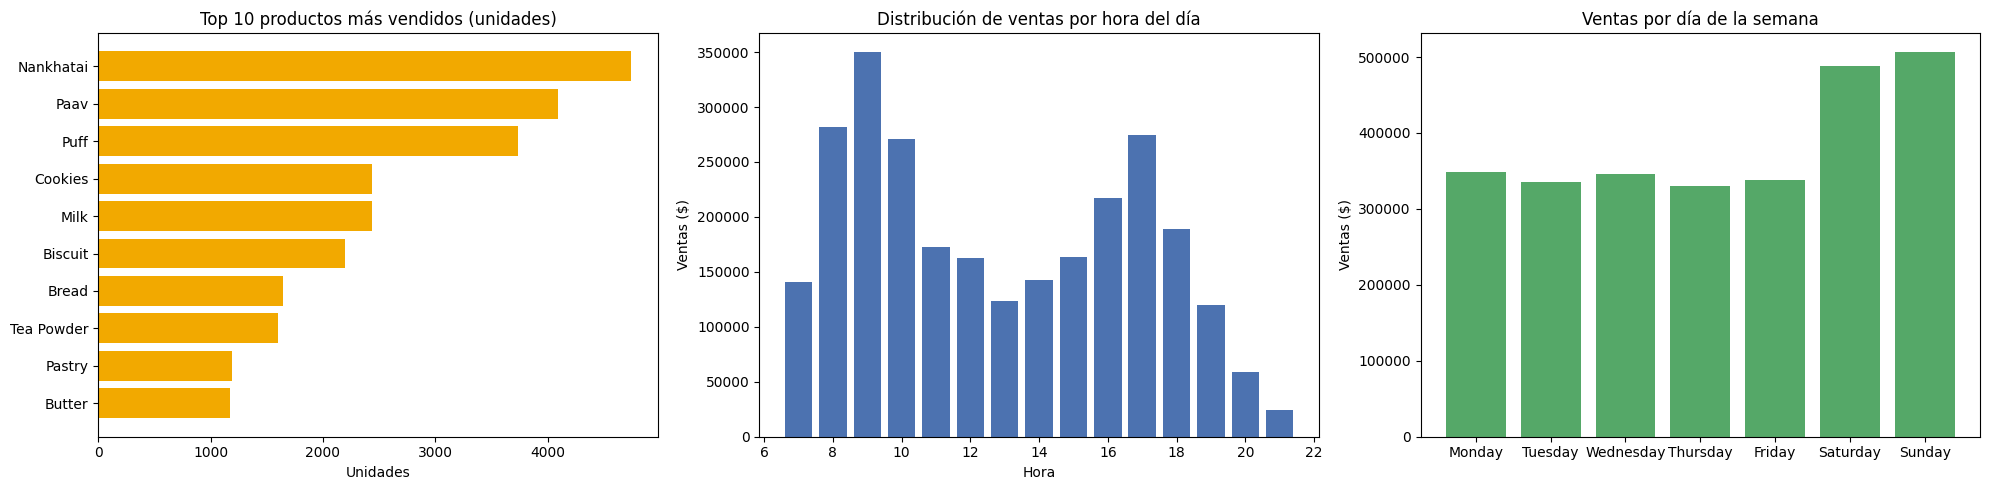

In [0]:
# Gráfico 1 — Top 10 productos más vendidos y distribución de ventas por hora/día
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

silver = spark.table(f"{FULL}.silver_bakery_sales")

top10 = (
    silver.groupBy("Product").agg(F.sum("Quantity").alias("unidades"))
    .orderBy(F.desc("unidades")).limit(10).toPandas().sort_values("unidades")
)
by_hour = (
    silver.groupBy("hour").agg(F.round(F.sum("total_sale"), 0).alias("ventas"))
    .orderBy("hour").toPandas()
)
orden_dias = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_dow = silver.groupBy("day_of_week").agg(F.round(F.sum("total_sale"), 0).alias("ventas")).toPandas()
by_dow["day_of_week"] = pd.Categorical(by_dow["day_of_week"], categories=orden_dias, ordered=True)
by_dow = by_dow.sort_values("day_of_week")

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].barh(top10["Product"], top10["unidades"], color="#F2A900")
axes[0].set_title("Top 10 productos más vendidos (unidades)")
axes[0].set_xlabel("Unidades")

axes[1].bar(by_hour["hour"], by_hour["ventas"], color="#4C72B0")
axes[1].set_title("Distribución de ventas por hora del día")
axes[1].set_xlabel("Hora")
axes[1].set_ylabel("Ventas ($)")

axes[2].bar(by_dow["day_of_week"].astype(str), by_dow["ventas"], color="#55A868")
axes[2].set_title("Ventas por día de la semana")
axes[2].set_ylabel("Ventas ($)")

plt.tight_layout()
plt.show()

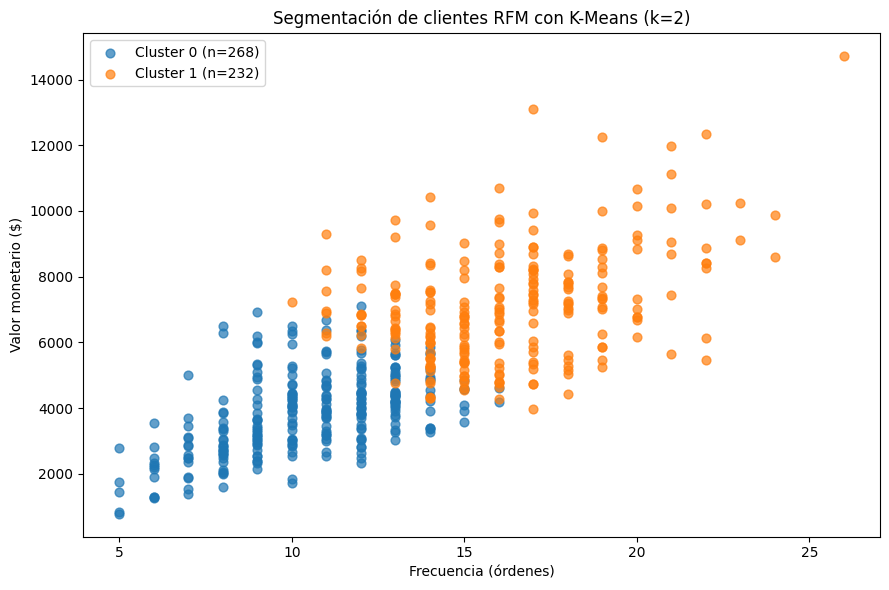

In [0]:
# Gráfico 2 — Dispersión de los clústeres de clientes (RFM)
import matplotlib.pyplot as plt

seg = spark.table(f"{FULL}.gold_customer_segments").toPandas()
k_usado = seg["cluster"].nunique()

fig, ax = plt.subplots(figsize=(9, 6))
for c in sorted(seg["cluster"].unique()):
    sub = seg[seg["cluster"] == c]
    ax.scatter(sub["frequency"], sub["monetary"], s=40, alpha=0.7, label=f"Cluster {c} (n={len(sub)})")

ax.set_xlabel("Frecuencia (órdenes)")
ax.set_ylabel("Valor monetario ($)")
ax.set_title(f"Segmentación de clientes RFM con K-Means (k={k_usado})")
ax.legend()
plt.tight_layout()
plt.show()

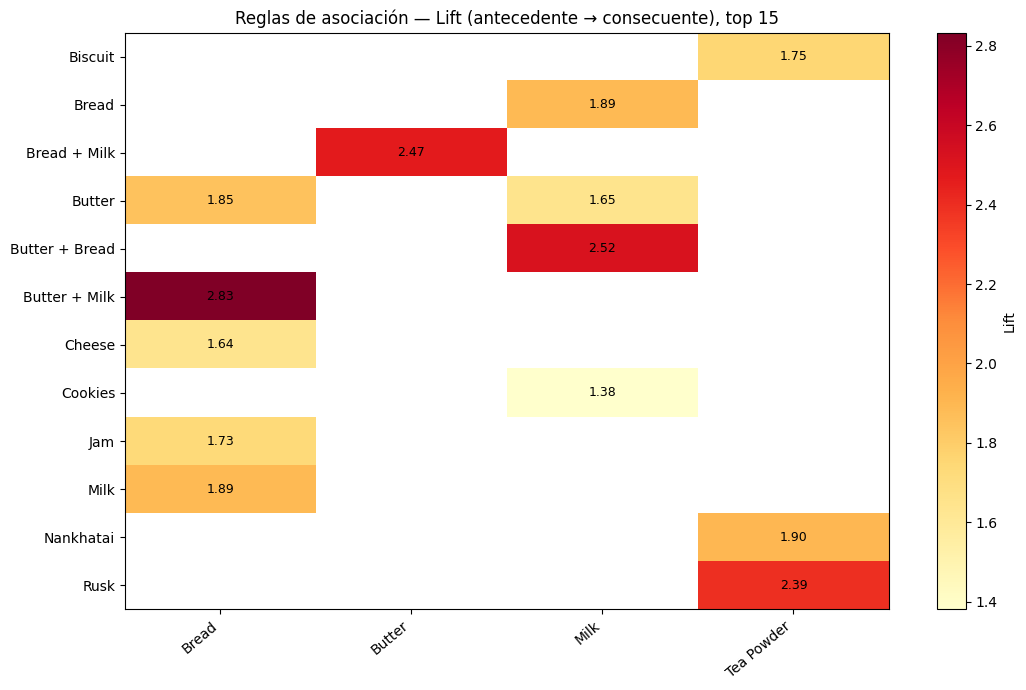

In [0]:
# Gráfico 3 — Matriz de calor de las reglas de asociación más relevantes
import numpy as np
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

top_rules = (
    spark.table(f"{FULL}.gold_association_rules")
    .orderBy(F.desc("lift")).limit(15).toPandas()
)

mat = top_rules.pivot(index="antecedente", columns="consecuente", values="lift")
data = mat.values.astype(float)

fig, ax = plt.subplots(figsize=(11, 7))
im = ax.imshow(data, cmap="YlOrRd", aspect="auto")

ax.set_xticks(range(len(mat.columns)))
ax.set_xticklabels(mat.columns, rotation=40, ha="right")
ax.set_yticks(range(len(mat.index)))
ax.set_yticklabels(mat.index)

for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        if not np.isnan(data[i, j]):
            ax.text(j, i, f"{data[i, j]:.2f}", ha="center", va="center", fontsize=9)

ax.set_title("Reglas de asociación — Lift (antecedente → consecuente), top 15")
plt.colorbar(im, ax=ax, label="Lift")
plt.tight_layout()
plt.show()